Train Accuracy: 90.49%
Test Accuracy: 89.34%


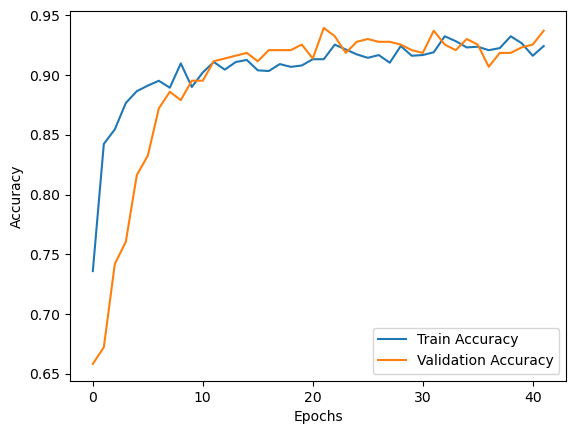

Model accuracy for prediction run after training: 93.95%


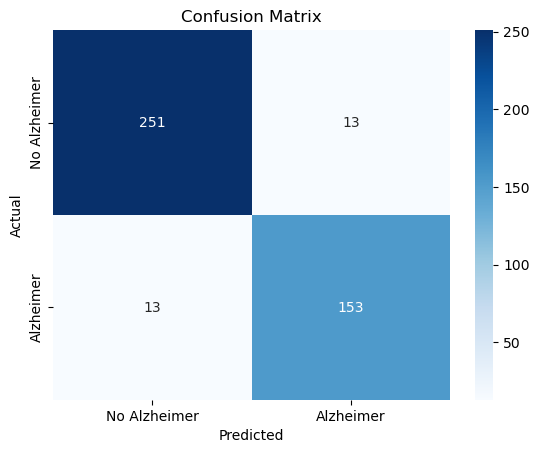

In [6]:

# Importing libraries and preprocessing data in this cell as we no longer need to make adjustments to data.
# All the tests from now on can use this preprocessed data

import os
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from keras import layers, Model
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix

# Ensure TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

# Loading dataset
data_url = "alzheimers_disease_data.csv"
data = pd.read_csv(data_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Splitting data into training and testing set
test_dataframe = dataframe.sample(frac=0.2, random_state=1337)
train_dataframe = dataframe.drop(test_dataframe.index)

# Convert dataframes to tf.data.Datasets
def dataframe_to_dataset(dataframe, target="Diagnosis"):
    dataframe = dataframe.copy()
    labels = dataframe.pop(target)
    ds = tf.data.Dataset.from_tensor_slices((dict(dataframe), labels))
    ds = ds.shuffle(buffer_size=len(dataframe)).batch(32)
    return ds

# Creating dataset objects for the dataframes
train_ds = dataframe_to_dataset(train_dataframe)
test_ds = dataframe_to_dataset(test_dataframe)

# Preprocessing layers for numerical and categorical features
def encode_feature(feature, name, dataset, is_string=False):
    lookup_class = layers.StringLookup if is_string else layers.IntegerLookup
    lookup = lookup_class(output_mode="binary")
    feature_ds = dataset.map(lambda x, y: x[name]).map(lambda x: tf.expand_dims(x, -1))
    lookup.adapt(feature_ds)
    return lookup(feature)

def normalize_feature(feature, name, dataset):
    normalizer = layers.Normalization()
    feature_ds = dataset.map(lambda x, y: tf.expand_dims(x[name], -1))
    normalizer.adapt(feature_ds)
    return normalizer(feature)

# Defining and encoding the features
inputs = {
    'SleepQuality': layers.Input(name='SleepQuality', shape=(1,), dtype='float32'),
    'MMSE': layers.Input(name='MMSE', shape=(1,), dtype='float32'),
    'FunctionalAssessment': layers.Input(name='FunctionalAssessment', shape=(1,), dtype='float32'),
    'MemoryComplaints': layers.Input(name='MemoryComplaints', shape=(1,), dtype='int64'),
    'BehavioralProblems': layers.Input(name='BehavioralProblems', shape=(1,), dtype='int64'),
    'ADL': layers.Input(name='ADL', shape=(1,), dtype='float32'),
    }

encoded_features = [
    encode_feature(inputs['MemoryComplaints'], 'MemoryComplaints', train_ds),
    encode_feature(inputs['BehavioralProblems'], 'BehavioralProblems', train_ds),
    normalize_feature(inputs['SleepQuality'], 'SleepQuality', train_ds),
    normalize_feature(inputs['MMSE'], 'MMSE', train_ds),
    normalize_feature(inputs['FunctionalAssessment'], 'FunctionalAssessment', train_ds),
    normalize_feature(inputs['ADL'], 'ADL', train_ds)
    ]

def build_model():
    # Concatenate all features and define the model layers
    all_features = layers.concatenate(encoded_features)
    x = layers.Dense(512, activation='relu')(all_features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(256,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(128,activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(64,activation='swish')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(32,activation='leaky_relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x) # dropout layer
    x = layers.Dense(16,activation='tanh')(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    # Compile the model
    model = Model(inputs, output)
    model.compile(optimizer='adam', loss='binary_crossentropy',
    metrics=['accuracy'])
    return model

# Using EarlyStopping callback to avoid overfitting with larger numbers of epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True, mode='min')

# Initialiazing the model
model = build_model()

# Training the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, callbacks=early_stopping, verbose=0)

# Evaluating the model accuracy for train and test datasets while training
sum_accuracy = sum(history.history["accuracy"])
train_accuracy = sum_accuracy / len(history.history["val_accuracy"])
print(f"Train Accuracy: {train_accuracy * 100:.2f}%")
sum_val_accuracy = sum(history.history["val_accuracy"])
model_accuracy = sum_val_accuracy / len(history.history["val_accuracy"])
print(f"Test Accuracy: {model_accuracy * 100:.2f}%")

# Plot training history
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Lists for true and predicted values of test data
test_true = []
test_pred = []

# Extracting data from test dataset and making predictions
for batch in test_ds:
    X_batch, y_batch = batch
    predictions = model.predict(X_batch, verbose=0)
    test_true.extend(y_batch.numpy())
    test_pred.extend(predictions.flatten())

# Getting values from numpy objects
test_true = np.array(test_true)
test_pred = np.array(test_pred)
# Converting predictions probabilities to binary
test_pred = (test_pred > 0.5).astype(int)

# Model accuracy for prediction
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"Model accuracy for prediction run after training: {pred_accuracy * 100:.2f}%")

# Plotting confusion matrix to show actual and predicted values for both classes
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



Accuracy: 95.12%


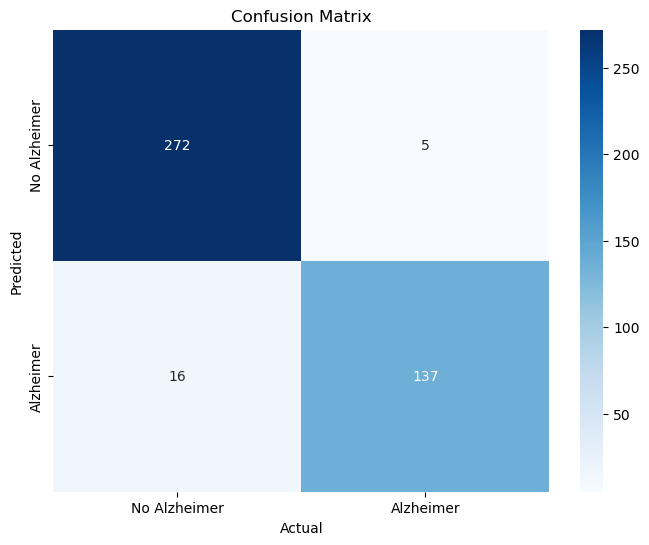

In [24]:
# Importing all the libraries and setting up training and testing dataframes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Loading dataset
file_url = "alzheimers_disease_data.csv"
data = pd.read_csv(file_url)
dataframe = data[["SleepQuality","MMSE","FunctionalAssessment","MemoryComplaints","BehavioralProblems","ADL","Diagnosis"]]

# Separating features and target and converting to a numpy object
x = dataframe.iloc[:, :-1].values
y = dataframe.iloc[:, -1].values

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Preprocessing - Applying StandardScaler() to datasets
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Building the model
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

# Model accuracy for prediction
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Plotting confusion matrix to show actual and predicted values for both classes
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'])
plt.title('Confusion Matrix')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()




----------------------------------------------------------------------------------------------------

Prediction Accuracy Comparison

Neural Network prediction accuracy: 93.95%

Random Forest prediction accuracy: 95.12%

----------------------------------------------------------------------------------------------------


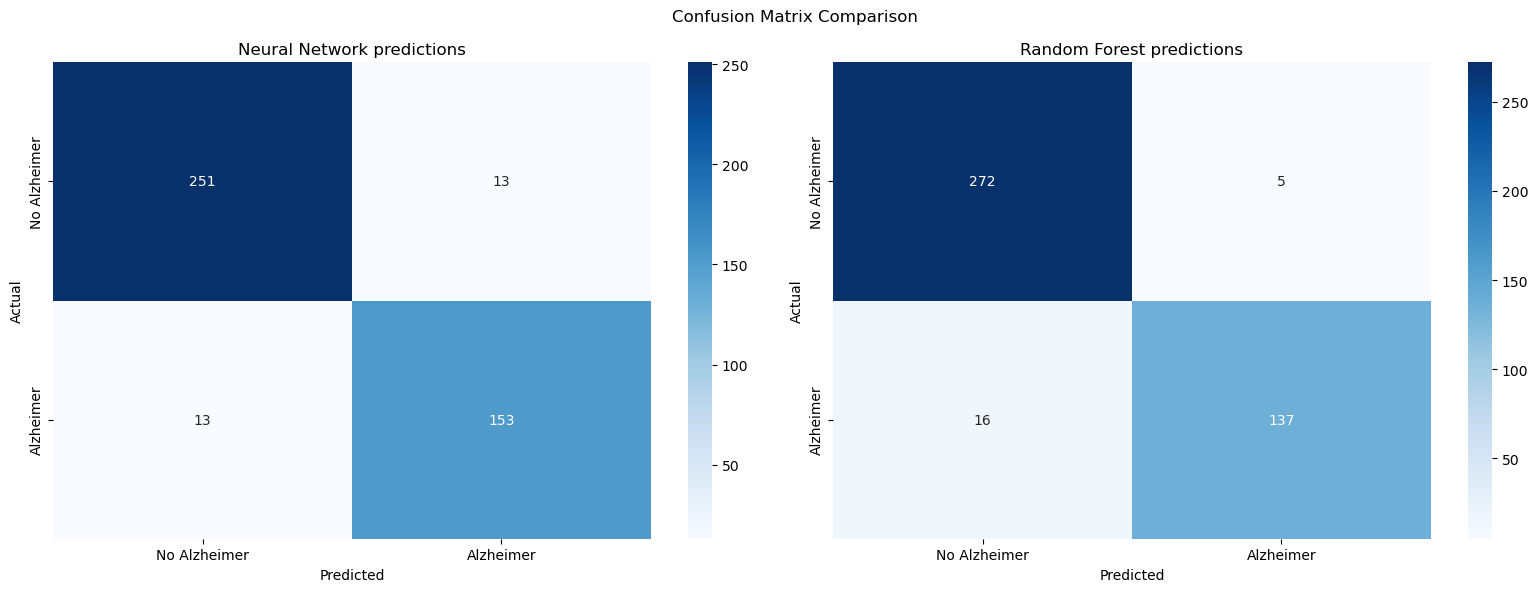

----------------------------------------------------------------------------------------------------


In [28]:
# Plotting prediction accuracy and confusion matrix of both models together
print("-"*100)

# Prediction accuracies
print("\nPrediction Accuracy Comparison")

# Neural Network prediction accuracy
pred_accuracy = accuracy_score(test_true, test_pred)
print(f"\nNeural Network prediction accuracy: {pred_accuracy * 100:.2f}%")

# Random Forest prediction accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'\nRandom Forest prediction accuracy: {accuracy * 100:.2f}%\n')

print("-"*100)

# Confusion matrix

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plotting confusion matrix for Neural Network
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'], ax=axes[0])
axes[0].set_title('Neural Network predictions')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Plotting confusion matrix for Random Forest
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=['No Alzheimer', 'Alzheimer'], yticklabels=['No Alzheimer', 'Alzheimer'], ax=axes[1])
axes[1].set_title('Random Forest predictions')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()
print("-"*100)
